In [13]:
import numpy as np
import csv
import pandas as pd
from scipy.signal import find_peaks
#import seaborn as sns
import matplotlib.pyplot as plt
import scipy as sp
import os
from pathlib import Path

In [14]:
SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output/UMAP/"))
if not os.path.exists(SAVEDIR):
    os.mkdir(SAVEDIR)

Import all the data

In [15]:
#UMAP stochastic
embedding_prot_erl_7_7_1_1 = pd.read_csv(str(SAVEDIR) + '\\embedding_erl_4-9_1_1.csv',header=None)
embedding_prot_erl_7_7_2_1 = pd.read_csv(str(SAVEDIR) + '\\embedding_erl_4-9_2_1.csv',header=None)
embedding_prot_erl_7_7_3_1 = pd.read_csv(str(SAVEDIR) + '\\embedding_erl_4-9_3_1.csv',header=None)

#prot stochastic
all_prot_erl_7_7_1_1 = pd.read_csv(str(SAVEDIR) + '\\all_prot_erl_4-9_1_1.csv',header=None)
all_prot_erl_7_7_2_1 = pd.read_csv(str(SAVEDIR) + '\\all_prot_erl_4-9_2_1.csv',header=None)
all_prot_erl_7_7_3_1 = pd.read_csv(str(SAVEDIR) + '\\all_prot_erl_4-9_3_1.csv',header=None)

In [16]:
#UMAP stochastic
embedding_prot_dmso_7_7_1_1 = pd.read_csv(str(SAVEDIR) + '\\embedding_dmso_4-9_1_1.csv',header=None)
embedding_prot_dmso_7_7_2_1 = pd.read_csv(str(SAVEDIR) + '\\embedding_dmso_4-9_2_1.csv',header=None)
embedding_prot_dmso_7_7_3_1 = pd.read_csv(str(SAVEDIR) + '\\embedding_dmso_4-9_3_1.csv',header=None)

#prot stochastic
all_prot_dmso_7_7_1_1 = pd.read_csv(str(SAVEDIR) + '\\all_prot_dmso_4-9_1_1.csv',header=None)
all_prot_dmso_7_7_2_1 = pd.read_csv(str(SAVEDIR) + '\\all_prot_dmso_4-9_2_1.csv',header=None)
all_prot_dmso_7_7_3_1 = pd.read_csv(str(SAVEDIR) + '\\all_prot_dmso_4-9_3_1.csv',header=None)

In [ ]:
# #UMAP stochastic

# embedding_prot_p21_2 = pd.read_csv(str(SAVEDIR) + '\\embedding_prot_p21_2.csv',header=None)
# embedding_prot_p21_4 = pd.read_csv(str(SAVEDIR) + '\\embedding_prot_p21_4.csv',header=None)
# embedding_prot_V2Me_2 = pd.read_csv(str(SAVEDIR) + '\\embedding_prot_V2Me_2.csv',header=None)
# embedding_prot_V2Me_4 = pd.read_csv(str(SAVEDIR) + '\\embedding_prot_V2Me_4.csv',header=None)

# #prot stochastic

# all_prot_p21_2 = pd.read_csv(str(SAVEDIR) + '\\all_prot_prot_p21_2.csv',header=None)
# all_prot_p21_4 = pd.read_csv(str(SAVEDIR) + '\\all_prot_prot_p21_4.csv',header=None)
# all_prot_V2Me_2 = pd.read_csv(str(SAVEDIR) + '\\all_prot_prot_V2Me_2.csv',header=None)
# all_prot_V2Me_4 = pd.read_csv(str(SAVEDIR) + '\\all_prot_prot_V2Me_4.csv',header=None)

In [158]:
embedding_prot_druge = pd.read_csv(str(SAVEDIR) + '\\embedding_drugE_stoch.csv',header=None)
all_prot_druge = pd.read_csv(str(SAVEDIR) + '\\all_prot_drugE_stoch.csv',header=None)

In [11]:
embedding_prot_p21inc = pd.read_csv(str(SAVEDIR) + '\\embedding_p21inc_stoch.csv',header=None)
all_prot_p21inc = pd.read_csv(str(SAVEDIR) + '\\all_prot_p21inc_stoch.csv',header=None)

In [6]:
embedding_prot_rb_drug = pd.read_csv(str(SAVEDIR) + '\\embedding_rb_drug_stoch.csv',header=None)
all_prot_rb_drug = pd.read_csv(str(SAVEDIR) + '\\all_prot_rb_drug_stoch.csv',header=None)

In [7]:
#times

all_time_stoch = pd.read_csv(str(SAVEDIR) + '\\all_time_erl_4-9_1_1.csv',header=None)
all_time_at_stoch = pd.read_csv(str(SAVEDIR) + '\\all_time_at_erl_4-9_1_1.csv',header=None)

In [17]:
embedding_tmp = np.loadtxt(str(SAVEDIR) + '\\embedding_all_ode.csv', delimiter=',')
embedding_index = np.loadtxt(str(SAVEDIR) + '\\embedding_all_ode_index.csv', delimiter=',')

This function ensures that the data has alternating cyclin E - cdc20 peaks. You will have to change find peaks based on the size of the window (peaks_E for example: 11*window_size+(window_size/2) and peaks_cdc: 17*window_size+(window_size/2)

In [18]:
window_size = len(all_prot_erl_7_7_3_1.columns)/18
cyce=int((window_size*11+window_size/2)-1)
cdc20=int((window_size*17+window_size/2)-1)

In [19]:
cyce

459

In [20]:
def restructProt(protDF, embedDF, timeDF):
    peaks_E, _ = find_peaks(protDF[cyce], prominence = 40/200, distance = 10)
    peaks_cdc, _ = find_peaks(protDF[cdc20], prominence = 40/200, distance = 10)
    
    mit_win = pd.DataFrame()
    time_win = pd.DataFrame()
    umap_win = pd.DataFrame()
    
    for n in range(2,len(peaks_cdc)-3):   #make sure we have divisions at ends 
        tmp_mit = peaks_cdc[n]
        tmp_mit2 = peaks_cdc[n+1]
        tmp_mit3 = peaks_cdc[n+2]
        tmp_mit4 = peaks_cdc[n+3]
        
        tmp_g1_s = peaks_E[(tmp_mit < peaks_E) & (peaks_E < tmp_mit2)]
        tmp_g1_s_2 = peaks_E[(tmp_mit2 < peaks_E) & (peaks_E < tmp_mit3)]
        tmp_g1_s_3 = peaks_E[(tmp_mit3 < peaks_E) & (peaks_E < tmp_mit4)]    
             
        if (np.size(tmp_g1_s) > 0) & (np.size(tmp_g1_s_2)>0) & (np.size(tmp_g1_s_3)>0):
            ordered = [tmp_mit, tmp_g1_s[0], tmp_mit2, tmp_g1_s_2[0], tmp_mit3, tmp_g1_s_3[0], tmp_mit4]
            g1_len_tmp = np.array(timeDF.iloc[ordered[3],0]) - np.array(timeDF.iloc[[ordered[2]],0])
            tmp_prot = protDF.iloc[int(ordered[1]):int(ordered[3]),:]
            tmp_umap = embedDF.iloc[int(ordered[1]):int(ordered[3]),:]
            tmp_time = timeDF.iloc[int(ordered[1]):int(ordered[3]),:]
            tmp = [g1_len_tmp]*len(tmp_time)
            tmp = np.concatenate(tmp, axis=0)
            tmp_time.insert(1, 'G1', tmp)
            
            mit_win = pd.concat([mit_win,tmp_prot],ignore_index=True)
            time_win = pd.concat([time_win, tmp_time], ignore_index=True)
            umap_win = pd.concat([umap_win, tmp_umap], ignore_index=True)
            
    return mit_win, time_win, umap_win

In [21]:
mit_win_erl_1_1, time_win_erl_1_1, umap_win_erl_1_1 = restructProt(all_prot_erl_7_7_1_1, embedding_prot_erl_7_7_1_1, all_time_at_stoch)
mit_win_erl_2_1, time_win_erl_2_1, umap_win_erl_2_1 = restructProt(all_prot_erl_7_7_2_1, embedding_prot_erl_7_7_2_1, all_time_at_stoch)
mit_win_erl_3_1, time_win_erl_3_1, umap_win_erl_3_1 = restructProt(all_prot_erl_7_7_3_1, embedding_prot_erl_7_7_3_1, all_time_at_stoch)

In [22]:
mit_win_dmso_1_1, time_win_dmso_1_1, umap_win_dmso_1_1 = restructProt(all_prot_dmso_7_7_1_1, embedding_prot_dmso_7_7_1_1, all_time_at_stoch)
mit_win_dmso_2_1, time_win_dmso_2_1, umap_win_dmso_2_1 = restructProt(all_prot_dmso_7_7_2_1, embedding_prot_dmso_7_7_2_1, all_time_at_stoch)
mit_win_dmso_3_1, time_win_dmso_3_1, umap_win_dmso_3_1 = restructProt(all_prot_dmso_7_7_3_1, embedding_prot_dmso_7_7_3_1, all_time_at_stoch)

In [ ]:
mit_win_p21_2, time_win_p21_2, umap_win_p21_2 = restructProt(all_prot_p21_2, embedding_prot_p21_2, all_time_at_stoch)
mit_win_p21_4, time_win_p21_4, umap_win_p21_4 = restructProt(all_prot_p21_4, embedding_prot_p21_4, all_time_at_stoch)

mit_win_V2Me_2, time_win_V2Me_2, umap_win_V2Me_2 = restructProt(all_prot_V2Me_2, embedding_prot_V2Me_2, all_time_at_stoch)
mit_win_V2Me_4, time_win_V2Me_4, umap_win_V2Me_4 = restructProt(all_prot_V2Me_4, embedding_prot_V2Me_4, all_time_at_stoch)

In [142]:
mit_win_drugb, time_win_drugb, umap_win_drugb = restructProt(all_prot_drugb, embedding_prot_drugb, all_time_at_stoch)

In [159]:
mit_win_druge, time_win_druge, umap_win_druge = restructProt(all_prot_druge, embedding_prot_druge, all_time_at_stoch)

In [12]:
mit_win_p21inc, time_win_p21inc, umap_win_p21inc = restructProt(all_prot_p21inc, embedding_prot_p21inc, all_time_at_stoch)

In [23]:
mit_win_rbdrug, time_win_rbdrug, umap_win_rbdrug = restructProt(all_prot_rb_drug, embedding_prot_rb_drug, all_time_at_stoch)

In [24]:
size = (4,4)
xmin = -5
xmax = 15
ymin = -5
ymax = 15
wid = 1

C:\Users\olesk\AppData\Local\Temp\ipykernel_19760\4123590857.py:19: DeprecationWarning: Please use `gaussian_filter` from the `scipy.ndimage` namespace, the `scipy.ndimage.filters` namespace is deprecated.
  H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')


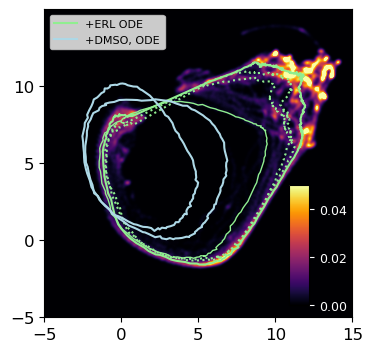

In [65]:
fig = plt.figure(figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

xmin, xmax = -5, 15
ymin, ymax = -5, 15

x = np.array(umap_win_erl_1_1[0])
y = np.array(umap_win_erl_1_1[1])
H, xedges, yedges = np.histogram2d(x, y, bins=1000, range= [[xmin,xmax], [ymin,ymax]], density=True)
# Apply gaussian filter
sigma = [5, 5]
H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')
#H2[H2>0.01] = 0


# fig = plt.figure()
# ax = fig.gca()
#ax.set_xlim(xmin, xmax)
#ax.set_ylim(ymin, ymax)
# fig.set_size_inches(5, 5)
im = plt.imshow((np.rot90(H2)), extent=[xmin, xmax, ymin, ymax], cmap='inferno')
im.set_clim(0, 0.05)
ind = np.where(embedding_index == 1) 
x=np.ndarray.tolist(embedding_tmp[ind,0])
y=np.ndarray.tolist(embedding_tmp[ind,1])
plt.plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='lightgreen', label='+ERL ODE')
ind = np.where(embedding_index == 112) 
x112=np.ndarray.tolist(embedding_tmp[ind,0])
y112=np.ndarray.tolist(embedding_tmp[ind,1])
plt.plot(x112[0][int(len(x112[0])/2):], y112[0][int(len(x112[0])/2):], color='lightgreen', lw=1.5, linestyle = 'dotted')
ind = np.where(embedding_index == 113) 
x=np.ndarray.tolist(embedding_tmp[ind,0])
y=np.ndarray.tolist(embedding_tmp[ind,1])
plt.plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='lightgreen', lw=1.5, linestyle = 'dotted')
ind = np.where(embedding_index == 1000) 
x=np.ndarray.tolist(embedding_tmp[ind,0])
y=np.ndarray.tolist(embedding_tmp[ind,1])
plt.plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='lightgreen', lw=1)
ind = np.where(embedding_index == 1001) 
x=np.ndarray.tolist(embedding_tmp[ind,0])
y=np.ndarray.tolist(embedding_tmp[ind,1])
plt.plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='lightblue', label='+DMSO, ODE')
ind = np.where(embedding_index == 2000) 
x=np.ndarray.tolist(embedding_tmp[ind,0])
y=np.ndarray.tolist(embedding_tmp[ind,1])
plt.plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='lightblue')


plt.yticks([-5, 0, 5, 10])
plt.legend(loc=2, fontsize=8)

cbar_ax = fig.add_axes([0.74, 0.14, 0.05, 0.3])
cb = fig.colorbar(im, cax=cbar_ax)
cb.ax.tick_params(labelsize=9)
cb.ax.yaxis.set_tick_params(color='white')
plt.setp(plt.getp(cb.ax.axes, 'yticklabels'), color='white')


            
fig5a_hm = Path(SAVEDIR, 'fig5a_hm.svg')
plt.savefig(fig5a_hm, bbox_inches='tight')



C:\Users\olesk\AppData\Local\Temp\ipykernel_19760\3037503996.py:19: DeprecationWarning: Please use `gaussian_filter` from the `scipy.ndimage` namespace, the `scipy.ndimage.filters` namespace is deprecated.
  H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')


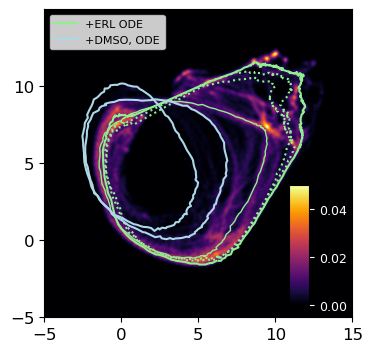

In [71]:
fig = plt.figure(figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

xmin, xmax = -5, 15
ymin, ymax = -5, 15

x = np.array(umap_win_erl_2_1[0])
y = np.array(umap_win_erl_2_1[1])
H, xedges, yedges = np.histogram2d(x, y, bins=1000, range= [[xmin,xmax], [ymin,ymax]], density=True)
# Apply gaussian filter
sigma = [5, 5]
H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')
#H2[H2>0.01] = 0


# fig = plt.figure()
# ax = fig.gca()
#ax.set_xlim(xmin, xmax)
#ax.set_ylim(ymin, ymax)
# fig.set_size_inches(5, 5)
im = plt.imshow((np.rot90(H2)), extent=[xmin, xmax, ymin, ymax], cmap='inferno')
im.set_clim(0, 0.05)
ind = np.where(embedding_index == 1) 
x=np.ndarray.tolist(embedding_tmp[ind,0])
y=np.ndarray.tolist(embedding_tmp[ind,1])
plt.plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='lightgreen', label='+ERL ODE')
ind = np.where(embedding_index == 112) 
x112=np.ndarray.tolist(embedding_tmp[ind,0])
y112=np.ndarray.tolist(embedding_tmp[ind,1])
plt.plot(x112[0][int(len(x112[0])/2):], y112[0][int(len(x112[0])/2):], color='lightgreen', lw=1.5, linestyle = 'dotted')
ind = np.where(embedding_index == 113) 
x=np.ndarray.tolist(embedding_tmp[ind,0])
y=np.ndarray.tolist(embedding_tmp[ind,1])
plt.plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='lightgreen', lw=1.5, linestyle = 'dotted')
ind = np.where(embedding_index == 1000) 
x=np.ndarray.tolist(embedding_tmp[ind,0])
y=np.ndarray.tolist(embedding_tmp[ind,1])
plt.plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='lightgreen', lw=1)
ind = np.where(embedding_index == 1001) 
x=np.ndarray.tolist(embedding_tmp[ind,0])
y=np.ndarray.tolist(embedding_tmp[ind,1])
plt.plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='lightblue', label='+DMSO, ODE')
ind = np.where(embedding_index == 2000) 
x=np.ndarray.tolist(embedding_tmp[ind,0])
y=np.ndarray.tolist(embedding_tmp[ind,1])
plt.plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='lightblue')


plt.yticks([-5, 0, 5, 10])
plt.legend(loc=2, fontsize=8)

cbar_ax = fig.add_axes([0.74, 0.14, 0.05, 0.3])
cb = fig.colorbar(im, cax=cbar_ax)
cb.ax.tick_params(labelsize=9)
cb.ax.yaxis.set_tick_params(color='white')
plt.setp(plt.getp(cb.ax.axes, 'yticklabels'), color='white')


            
fig5a_hm = Path(SAVEDIR, 'fig5a_hm.svg')
plt.savefig(fig5a_hm, bbox_inches='tight')



C:\Users\olesk\AppData\Local\Temp\ipykernel_19760\2070889701.py:19: DeprecationWarning: Please use `gaussian_filter` from the `scipy.ndimage` namespace, the `scipy.ndimage.filters` namespace is deprecated.
  H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')


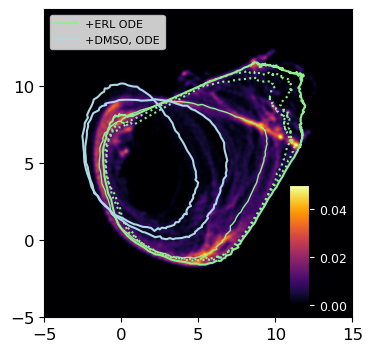

In [72]:
fig = plt.figure(figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

xmin, xmax = -5, 15
ymin, ymax = -5, 15

x = np.array(umap_win_erl_3_1[0])
y = np.array(umap_win_erl_3_1[1])
H, xedges, yedges = np.histogram2d(x, y, bins=1000, range= [[xmin,xmax], [ymin,ymax]], density=True)
# Apply gaussian filter
sigma = [5, 5]
H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')
#H2[H2>0.01] = 0


# fig = plt.figure()
# ax = fig.gca()
#ax.set_xlim(xmin, xmax)
#ax.set_ylim(ymin, ymax)
# fig.set_size_inches(5, 5)
im = plt.imshow((np.rot90(H2)), extent=[xmin, xmax, ymin, ymax], cmap='inferno')
im.set_clim(0, 0.05)
ind = np.where(embedding_index == 1) 
x=np.ndarray.tolist(embedding_tmp[ind,0])
y=np.ndarray.tolist(embedding_tmp[ind,1])
plt.plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='lightgreen', label='+ERL ODE')
ind = np.where(embedding_index == 112) 
x112=np.ndarray.tolist(embedding_tmp[ind,0])
y112=np.ndarray.tolist(embedding_tmp[ind,1])
plt.plot(x112[0][int(len(x112[0])/2):], y112[0][int(len(x112[0])/2):], color='lightgreen', lw=1.5, linestyle = 'dotted')
ind = np.where(embedding_index == 113) 
x=np.ndarray.tolist(embedding_tmp[ind,0])
y=np.ndarray.tolist(embedding_tmp[ind,1])
plt.plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='lightgreen', lw=1.5, linestyle = 'dotted')
ind = np.where(embedding_index == 1000) 
x=np.ndarray.tolist(embedding_tmp[ind,0])
y=np.ndarray.tolist(embedding_tmp[ind,1])
plt.plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='lightgreen', lw=1)
ind = np.where(embedding_index == 1001) 
x=np.ndarray.tolist(embedding_tmp[ind,0])
y=np.ndarray.tolist(embedding_tmp[ind,1])
plt.plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='lightblue', label='+DMSO, ODE')
ind = np.where(embedding_index == 2000) 
x=np.ndarray.tolist(embedding_tmp[ind,0])
y=np.ndarray.tolist(embedding_tmp[ind,1])
plt.plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='lightblue')


plt.yticks([-5, 0, 5, 10])
plt.legend(loc=2, fontsize=8)

cbar_ax = fig.add_axes([0.74, 0.14, 0.05, 0.3])
cb = fig.colorbar(im, cax=cbar_ax)
cb.ax.tick_params(labelsize=9)
cb.ax.yaxis.set_tick_params(color='white')
plt.setp(plt.getp(cb.ax.axes, 'yticklabels'), color='white')


            
fig5a_hm = Path(SAVEDIR, 'fig5a_hm.svg')
plt.savefig(fig5a_hm, bbox_inches='tight')



C:\Users\olesk\AppData\Local\Temp\ipykernel_19760\3508363220.py:9: DeprecationWarning: Please use `gaussian_filter` from the `scipy.ndimage` namespace, the `scipy.ndimage.filters` namespace is deprecated.
  H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')


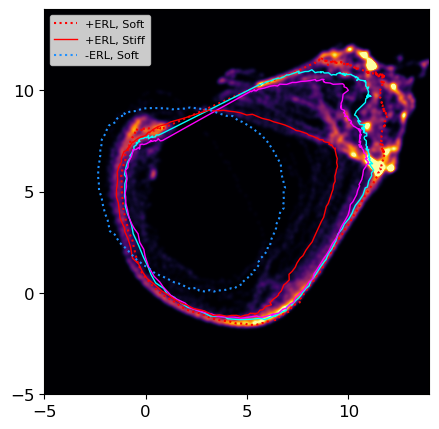

In [26]:
xmin, xmax = -5, 14
ymin, ymax = -5, 14

x = np.array(umap_win_rbdrug[0])
y = np.array(umap_win_rbdrug[1])
H, xedges, yedges = np.histogram2d(x, y, bins=1000, range= [[xmin,xmax], [ymin,ymax]], density=True)
# Apply gaussian filter
sigma = [5, 5]
H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')
#H2[H2>0.01] = 0


fig = plt.figure()
ax = fig.gca()
#ax.set_xlim(xmin, xmax)
#ax.set_ylim(ymin, ymax)
fig.set_size_inches(5, 5)
plt.imshow((np.rot90(H2)), extent=[xmin, xmax, ymin, ymax], cmap='inferno')

ind = np.where(embedding_index == 1) 
x=np.ndarray.tolist(embedding_tmp[ind,0])
y=np.ndarray.tolist(embedding_tmp[ind,1])
plt.plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='red', lw=1.5, linestyle = 'dotted', label='+ERL, Soft')
ind = np.where(embedding_index == 112) 
x112=np.ndarray.tolist(embedding_tmp[ind,0])
y112=np.ndarray.tolist(embedding_tmp[ind,1])
plt.plot(x112[0][int(len(x112[0])/2):], y112[0][int(len(x112[0])/2):], color='cyan', lw=1)
ind = np.where(embedding_index == 113) 
x=np.ndarray.tolist(embedding_tmp[ind,0])
y=np.ndarray.tolist(embedding_tmp[ind,1])
plt.plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='magenta', lw=1)
ind = np.where(embedding_index == 1000) 
x=np.ndarray.tolist(embedding_tmp[ind,0])
y=np.ndarray.tolist(embedding_tmp[ind,1])
plt.plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='red', lw=1, label='+ERL, Stiff')
ind = np.where(embedding_index == 1001) 
x=np.ndarray.tolist(embedding_tmp[ind,0])
y=np.ndarray.tolist(embedding_tmp[ind,1])
plt.plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='dodgerblue', lw=1.5, linestyle = 'dotted', label='-ERL, Soft')
plt.yticks([-5, 0, 5, 10])
plt.legend(loc=2, fontsize=8)

plt.clim(0, 0.05)



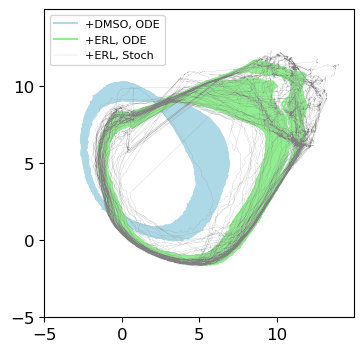

In [74]:
fig = plt.figure(figsize=(4,4))

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

xmin, xmax = -5, 15
ymin, ymax = -5, 15
ind = np.where(embedding_index == 1) 
x=np.ndarray.tolist(embedding_tmp[ind,0])
y=np.ndarray.tolist(embedding_tmp[ind,1])

for ii in range(1001,2001):
    ind = np.where(embedding_index == ii) 
    x=np.ndarray.tolist(embedding_tmp[ind,0])
    y=np.ndarray.tolist(embedding_tmp[ind,1])
    plt.plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='lightblue')
ind = np.where(embedding_index == 1001) 
x=np.ndarray.tolist(embedding_tmp[ind,0])
y=np.ndarray.tolist(embedding_tmp[ind,1])
plt.plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='lightblue', label='+DMSO, ODE')

for ii in range(1001):
    ind = np.where(embedding_index == ii) 
    x=np.ndarray.tolist(embedding_tmp[ind,0])
    y=np.ndarray.tolist(embedding_tmp[ind,1])
    plt.plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='lightgreen')
ind = np.where(embedding_index == 1) 
x=np.ndarray.tolist(embedding_tmp[ind,0])
y=np.ndarray.tolist(embedding_tmp[ind,1])
plt.plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='lightgreen', label='+ERL, ODE')
    
plt.plot(umap_win_rbdrug.iloc[:,0], umap_win_rbdrug.iloc[:,1], lw=0.1, color='grey', label='+ERL, Stoch')

plt.xlim([xmin, xmax])
plt.ylim([ymin, ymax])
plt.xticks([-5, 0, 5, 10])
plt.yticks([-5, 0, 5, 10])

plt.legend(loc=2, fontsize=8)


C:\Users\olesk\AppData\Local\Temp\ipykernel_13160\3294315662.py:9: DeprecationWarning: Please use `gaussian_filter` from the `scipy.ndimage` namespace, the `scipy.ndimage.filters` namespace is deprecated.
  H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')


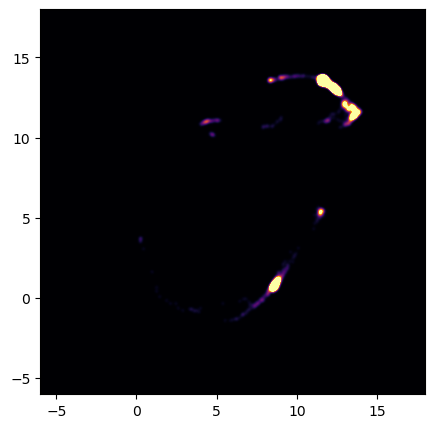

In [14]:
xmin, xmax = -6, 18
ymin, ymax = -6, 18

x = np.array(umap_win_p21inc[0])
y = np.array(umap_win_p21inc[1])
H, xedges, yedges = np.histogram2d(x, y, bins=500, range= [[-6,18], [-6,18]], density=True)
# Apply gaussian filter
sigma = [2, 2]
H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')
#H2[H2>0.01] = 0


fig = plt.figure()
ax = fig.gca()
#ax.set_xlim(xmin, xmax)
#ax.set_ylim(ymin, ymax)
fig.set_size_inches(5, 5)
plt.imshow((np.rot90(H2)), extent=[xmin, xmax, ymin, ymax], cmap='inferno')

plt.clim(0, 0.02)


In [ ]:
xmin, xmax = -6, 18
ymin, ymax = -6, 18

x = np.array(umap_win_p21_4[0])
y = np.array(umap_win_p21_4[1])
H, xedges, yedges = np.histogram2d(x, y, bins=500, range= [[-6,18], [-6,18]], density=True)
# Apply gaussian filter
sigma = [2, 2]
H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')
#H2[H2>0.01] = 0


fig = plt.figure()
ax = fig.gca()
#ax.set_xlim(xmin, xmax)
#ax.set_ylim(ymin, ymax)
fig.set_size_inches(5, 5)
plt.imshow(np.rot90(np.rot90(H2)), extent=[xmin, xmax, ymin, ymax], cmap='inferno')

plt.clim(0, 0.02)


In [ ]:
xmin, xmax = -6, 18
ymin, ymax = -6, 18

x = np.array(umap_win_V2Me_4[0])
y = np.array(umap_win_V2Me_4[1])
H, xedges, yedges = np.histogram2d(x, y, bins=500, range= [[-6,18], [-6,18]], density=True)
# Apply gaussian filter
sigma = [2, 2]
H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')
#H2[H2>0.01] = 0


fig = plt.figure()
ax = fig.gca()
#ax.set_xlim(xmin, xmax)
#ax.set_ylim(ymin, ymax)
fig.set_size_inches(5, 5)
plt.imshow(np.rot90(np.rot90(H2)), extent=[xmin, xmax, ymin, ymax], cmap='inferno')

plt.clim(0, 0.02)
